In [69]:
##Analyze passenger usage by transportation method
# Calculate passenger usage by transportation mode

transport_usage = df.groupby("Mode_of_Transport").agg(
    Total_Trips=("Trip_ID", "count"),
    Total_Passengers=("Passenger_Count", "sum"),
    Average_Passengers=("Passenger_Count", "mean")
)

transport_usage = transport_usage.sort_values(
    by="Total_Passengers",
    ascending=False
)

print(transport_usage)

                   Total_Trips  Total_Passengers  Average_Passengers
Mode_of_Transport                                                   
Bus                        332           14936.0           49.131579
Ferry                      287           13104.0           50.015267
Train                      243            9851.0           46.909524
Tram                       138            6348.0           51.193548


In [70]:
#Evaluate the total number of trips by transport mode
# Count trips by transportation mode

total_trips = df.groupby("Mode_of_Transport")["Trip_ID"].nunique()

print(total_trips)

Mode_of_Transport
Bus      332
Ferry    287
Train    243
Tram     138
Name: Trip_ID, dtype: int64


In [71]:
#Evaluate total passenger volume
# Calculate total passengers by transport mode

total_passengers = (
    df.groupby("Mode_of_Transport")["Passenger_Count"]
    .sum()
    .sort_values(ascending=False)
)

print(total_passengers)

Mode_of_Transport
Bus      14936.0
Ferry    13104.0
Train     9851.0
Tram      6348.0
Name: Passenger_Count, dtype: float64


In [72]:
#Evaluate average passengers per trip
# Calculate average passengers per trip

average_passengers = (
    df.groupby("Mode_of_Transport")["Passenger_Count"]
    .mean()
    .sort_values(ascending=False)
)

print(average_passengers)

Mode_of_Transport
Tram     51.193548
Ferry    50.015267
Bus      49.131579
Train    46.909524
Name: Passenger_Count, dtype: float64


In [73]:
#Evaluate average trip duration
# Calculate average trip duration

average_duration = (
    df.groupby("Mode_of_Transport")["Trip_Duration_Minutes"]
    .mean()
    .sort_values(ascending=True)
)

print(average_duration)

Mode_of_Transport
Ferry    91.590038
Train    94.369863
Tram     95.074380
Bus      96.210702
Name: Trip_Duration_Minutes, dtype: float64


In [74]:
#Evaluate average fare by transportation method
# Calculate average fare

average_fare = (
    df.groupby("Mode_of_Transport")["Fare_Amount"]
    .mean()
    .sort_values(ascending=True)
)

print(average_fare)

Mode_of_Transport
Ferry    24.387883
Tram     25.240596
Bus      25.621147
Train    26.262932
Name: Fare_Amount, dtype: float64


In [75]:
#Combine all transportation performance indicators
# Compare performance across all transport modes

performance = df.groupby("Mode_of_Transport").agg(
    Total_Trips=("Trip_ID", "nunique"),

    Passenger_Records=("Passenger_Count", "count"),

    Total_Passengers=("Passenger_Count", "sum"),

    Average_Passengers=("Passenger_Count", "mean"),

    Average_Fare=("Fare_Amount", "mean"),

    Average_Duration=("Trip_Duration_Minutes", "mean")
)

# Round results to two decimal places
performance = performance.round(2)

# Display performance comparison
print(performance)

                   Total_Trips  Passenger_Records  Total_Passengers  \
Mode_of_Transport                                                     
Bus                        332                304           14936.0   
Ferry                      287                262           13104.0   
Train                      243                210            9851.0   
Tram                       138                124            6348.0   

                   Average_Passengers  Average_Fare  Average_Duration  
Mode_of_Transport                                                      
Bus                             49.13         25.62             96.21  
Ferry                           50.02         24.39             91.59  
Train                           46.91         26.26             94.37  
Tram                            51.19         25.24             95.07  


In [76]:
#Analyze how trip duration impacts customer experience
# Calculate average trip duration by transport mode

duration_analysis = df.groupby("Mode_of_Transport")[
    "Trip_Duration_Minutes"
].mean().sort_values()

print(duration_analysis)

Mode_of_Transport
Ferry    91.590038
Train    94.369863
Tram     95.074380
Bus      96.210702
Name: Trip_Duration_Minutes, dtype: float64


In [77]:
#Analyze how passenger count impacts customer experience
# Calculate average passenger count by transport mode

passenger_analysis = df.groupby("Mode_of_Transport")[
    "Passenger_Count"
].mean().sort_values(ascending=False)

print(passenger_analysis)

Mode_of_Transport
Tram     51.193548
Ferry    50.015267
Bus      49.131579
Train    46.909524
Name: Passenger_Count, dtype: float64


In [78]:
#Analyze how trip characteristics relate to one another
# Select numerical trip characteristics

trip_characteristics = df[
    [
        "Passenger_Count",
        "Fare_Amount",
        "Trip_Duration_Minutes",
        "Departure_Hour"
    ]
]

# Calculate correlation matrix

correlation = trip_characteristics.corr()

print(correlation)

                       Passenger_Count  Fare_Amount  Trip_Duration_Minutes  \
Passenger_Count                1.00000     0.015250               0.021590   
Fare_Amount                    0.01525     1.000000              -0.046738   
Trip_Duration_Minutes          0.02159    -0.046738               1.000000   
Departure_Hour                -0.00751     0.009004              -0.034764   

                       Departure_Hour  
Passenger_Count             -0.007510  
Fare_Amount                  0.009004  
Trip_Duration_Minutes       -0.034764  
Departure_Hour               1.000000  


In [79]:
#Analyze how trip characteristics relate to one another
# Select numerical trip characteristics

trip_characteristics = df[
    [
        "Passenger_Count",
        "Fare_Amount",
        "Trip_Duration_Minutes",
        "Departure_Hour"
    ]
]

# Calculate correlation matrix

correlation = trip_characteristics.corr()

print(correlation)

                       Passenger_Count  Fare_Amount  Trip_Duration_Minutes  \
Passenger_Count                1.00000     0.015250               0.021590   
Fare_Amount                    0.01525     1.000000              -0.046738   
Trip_Duration_Minutes          0.02159    -0.046738               1.000000   
Departure_Hour                -0.00751     0.009004              -0.034764   

                       Departure_Hour  
Passenger_Count             -0.007510  
Fare_Amount                  0.009004  
Trip_Duration_Minutes       -0.034764  
Departure_Hour               1.000000  


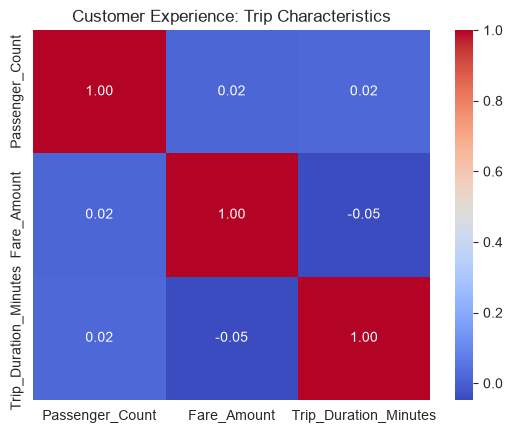

In [80]:
#Analyzing how trip characteristics impact customer experience
# Select numerical characteristics
variables = df[
    [
        "Passenger_Count",
        "Fare_Amount",
        "Trip_Duration_Minutes"
    ]
]

# Calculate correlations
correlation = variables.corr()

# Create heatmap
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Customer Experience: Trip Characteristics")
plt.show()